# Problem 1

In [19]:
import numpy as np
def var1(x: np.ndarray) -> float:
    mean = x.mean()
    a = x - mean
    n = len(a)
    var = sum(a**2)/(n-1)
    return var

def var2(x: np.ndarray) -> float:
    a = sum(x**2)
    n = len(x)
    b = sum(x)**2 / n
    return (a-b)/(n-1)

In [30]:
x = np.array([1,4,1])
print(f'check for x = (1,4,1):\nformula 1: {var1(x)}, formula 2: {var2(x)}, coincides with actual Var(x) = 3.0\n')
x = np.array([
    10_000_000.0,
    10_000_000.1,
    10_000_000.2
])
print(f'for x = (10,000,000.0, 10,000,000.1, 10,000,000.2):\n'
      f'formula 1: {var1(x)}, formula 2: {var2(x)}, actual Var(x) = 0.001')

check for x = (1,4,1):
formula 1: 3.0, formula 2: 3.0, coincides with actual Var(x) = 3.0

for x = (10,000,000.0, 10,000,000.1, 10,000,000.2):
formula 1: 0.009999999925494194, formula 2: -0.03125, actual Var(x) = 0.001


As we can see, formula 1 provides a more accurate result.

# Problem 2

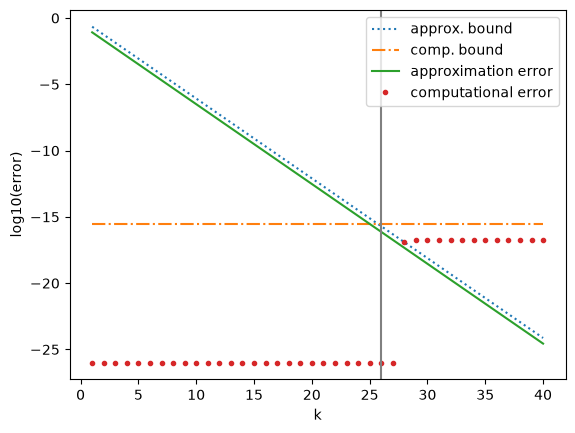

In [42]:
from fractions import Fraction
import math, numpy as np, matplotlib.pyplot as plt

eps, theta, R = 2.0**-53, 0.25, 1/3
C = 4/3 + 7*R/4
x_star = Fraction(1, 3)
k_min = math.floor(math.log(8 / (23 * eps), 4)) + 1   # the calculated k is at least 26

K = 40
x_fl, x_ex = 0.0, Fraction(0)
appr, comp = [], []
for k in range(1, K + 1):
    x_fl = (x_fl + 1.0) * 0.25
    x_ex = (x_ex + 1) / 4
    appr.append(abs(float(x_star - x_ex)))
    comp.append(abs(float(x_ex - Fraction(x_fl))))

kk = np.arange(1, K + 1)
lg = lambda v: np.log10(np.maximum(np.array(v, float), 1e-26))
plt.plot(kk, np.log10(2*R/(1-theta) * theta**kk), ":", label="approx. bound")
plt.plot(kk, np.log10(C/(1-theta) * eps) * np.ones(K), "-.", label="comp. bound")
plt.plot(kk, lg(appr), "-", label="approximation error")
plt.plot(kk, lg(comp), ".", label="computational error")
plt.axvline(k_min, color="gray")
plt.xlabel("k"); plt.ylabel("log10(error)"); plt.legend(); plt.show()